# Proyek Analisis Data: E-Commerce Public
- **Nama:** Juli Yawati Manalu
- **Email:** ds284b6x0855@student.devacademy.id
- **ID Dicoding:** DS284B6X0855

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk mana yang menyumbang pendapatan terbesar pada Januari-Agustus 2018, dan bagaimana pertumbuhannya dibandingkan periode Januari-Agustus 2017?

Keterangan
- **Specific:** Fokus pada pendapatan setiap kategori dan perbandingan periode Januari-Agustus 2018 dengan 2017.
- **Measurable:**	Menggunakan total nilai penjualan, kontribusi pendapatan, serta persentase pertumbuhan tiap tahun.
- **Action-Oriented:**	Membantu bisnis menentukan kategori produk yang perlu diprioritaskan dalam pengelolaan stok, promosi, dan strategi penjualan.
- **Relevant:**	Memahami kontribusi setiap kategori terhadap penjualan bisnis dan mendukung pengambilan keputusan.
- **Time-Bound:**	Analisis dibatasi pada Januari-Agustus 2018 dan dibandingkan dengan Januari-Agustus 2017.
---
- **Pertanyaan 2:** Bagaimana komposisi dan tren penggunaan metode pembayaran pelanggan setiap bulan, serta bagaimana perbedaan rata-rata nilai pembayaran dan jumlah cicilan berdasarkan metode pembayaran selama Januari 2017 hingga Agustus 2018?

Keterangan
- **Specific:**	Fokus pada penggunaan metode pembayaran dan perbedaan karakteristik pembayaran.
- **Measurable:** Jumlah pesanan setiap metode pembayaran, proporsi penggunaan, tren bulanan, rata-rata nilai pembayaran, dan rata-rata jumlah cicilan.
- **Action-Oriented:**	Memahami preferensi pembayaran pelanggan dan menentukan metode pembayaran yang perlu dipertahankan atau dikembangkan.
- **Relevant:**	Mendukung peningkatan kemudahan pembayaran.
- **Time-Bound:**	Dibatasi pada Januari 2017 hingga Agustus 2018.

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

sns.set_theme(style='whitegrid')

import matplotlib.ticker as mtick


## Data Wrangling

### Gathering Data

#### Memuat dataset

In [2]:
orders_df = pd.read_csv('orders_dataset.csv')
order_items_df = pd.read_csv('order_items_dataset.csv')
products_df = pd.read_csv('products_dataset.csv')
category_df = pd.read_csv('product_category_name_translation.csv')
payments_df = pd.read_csv('order_payments_dataset.csv')

datasets = {
    'Orders': orders_df,
    'Order Items': order_items_df,
    'Products': products_df,
    'Category Translation': category_df,
    'Order Payments': payments_df
}

for name, df in datasets.items():
    print(f'{name}: {df.shape[0]} baris, {df.shape[1]} kolom')

Orders: 99441 baris, 8 kolom
Order Items: 112650 baris, 7 kolom
Products: 32951 baris, 9 kolom
Category Translation: 71 baris, 2 kolom
Order Payments: 103886 baris, 5 kolom


**Insight:**
- Terdapat lima dataset yang digunakan: Orders (99.441 baris), Order Items (112.650 baris), Products (32.951 baris), Category Translation (71 baris), dan Order Payments (103.886 baris).
- Orders menjadi tabel pusat yang dapat dihubungkan dengan Order Items dan Order Payments melalui `order_id`. Order Items dihubungkan dengan Products melalui `product_id`, lalu Products dengan Category Translation melalui `product_category_name`.
- Satu pesanan dapat memiliki lebih dari satu item dan lebih dari satu catatan pembayaran (jumlah baris Order Items dan Order Payments lebih besar daripada Orders), sehingga penggabungan tabel perlu dilakukan dengan hati-hati agar tidak menggandakan nilai.


### Assessing Data

#### Mengidentifikasi masalah pada data

In [3]:
for name, df in datasets.items():
    print(f'\n{name.upper()}')
    df.info()


ORDERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

ORDER ITEMS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112

**Cek missing value dan duplikasi**

In [4]:
for name, df in datasets.items():
    print(f'\n{name.upper()}')

    print('\nMissing Values:')
    print(df.isnull().sum())

    print('\nJumlah baris duplikat:')
    print(df.duplicated().sum())


ORDERS

Missing Values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Jumlah baris duplikat:
0

ORDER ITEMS

Missing Values:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Jumlah baris duplikat:
0

PRODUCTS

Missing Values:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Jumlah baris duplikat:
0

CATEGORY TRANSL

**Cek missing value pada kolom tanggal berdasarkan status pesanan**

In [5]:
date_columns = [
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]

missing_by_status = (
    orders_df.groupby('order_status')[date_columns]
    .apply(lambda x: x.isnull().sum())
)
missing_by_status['total_pesanan'] = orders_df['order_status'].value_counts()

display(missing_by_status)


,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,total_pesanan
order_status,,,,
approved,0,2,2,2
canceled,141,550,619,625
created,5,5,5,5
delivered,14,2,8,96478
invoiced,0,314,314,314
processing,0,301,301,301
shipped,0,0,1107,1107
unavailable,0,609,609,609


**Invalid value**

In [6]:
print(' ORDER ITEMS ')
print('Price <= 0:',
      (order_items_df['price'] <= 0).sum())

print('Freight value < 0:',
      (order_items_df['freight_value'] < 0).sum())
print('Freight value = 0 (gratis ongkir):',
      (order_items_df['freight_value'] == 0).sum())

print('\n ORDER PAYMENTS ')
print('Payment value < 0:',
      (payments_df['payment_value'] < 0).sum())
print('Payment value = 0:',
      (payments_df['payment_value'] == 0).sum())
print('Metode pembayaran pada payment value = 0:')
print(payments_df.loc[
    payments_df['payment_value'] == 0, 'payment_type'
].value_counts().to_string())

print('\nPayment installments <= 0:',
      (payments_df['payment_installments'] <= 0).sum())


# Memeriksa kategori dan metode pembayaran
print('\n KATEGORI PRODUK ')
print(products_df['product_category_name'].value_counts(dropna=False).head(10))

print('\n METODE PEMBAYARAN')
print(payments_df['payment_type'].value_counts(dropna=False))


 ORDER ITEMS 
Price <= 0: 0
Freight value < 0: 0
Freight value = 0 (gratis ongkir): 383

 ORDER PAYMENTS 
Payment value < 0: 0
Payment value = 0: 9
Metode pembayaran pada payment value = 0:
payment_type
voucher        6
not_defined    3

Payment installments <= 0: 2

 KATEGORI PRODUK 
product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64

 METODE PEMBAYARAN
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64


In [7]:
print('PAYMENT INSTALLMENTS <= 0')
display(
    payments_df[
        payments_df['payment_installments'] <= 0
    ]
)

print('\n PAYMENT TYPE NOT_DEFINED')

display(
    payments_df[
        payments_df['payment_type'] == 'not_defined'
    ]
)

PAYMENT INSTALLMENTS <= 0


,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94



 PAYMENT TYPE NOT_DEFINED


,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0


**Outlier**

In [8]:
columns_to_check = {
    'Order Items': order_items_df[['price', 'freight_value']],
    'Order Payments': payments_df[['payment_value', 'payment_installments']]
}

for name, df in columns_to_check.items():
    print(f'\n{name.upper()}')

    for column in df.columns:
        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[
            (df[column] < lower_bound) |
            (df[column] > upper_bound)
        ]

        print(f'\nKolom: {column}')
        print(f'Batas bawah: {lower_bound:.2f}')
        print(f'Batas atas: {upper_bound:.2f}')
        print(f'Jumlah outlier: {len(outliers)}')


ORDER ITEMS

Kolom: price
Batas bawah: -102.60
Batas atas: 277.40
Jumlah outlier: 8427

Kolom: freight_value
Batas bawah: 0.98
Batas atas: 33.25
Jumlah outlier: 12134

ORDER PAYMENTS

Kolom: payment_value
Batas bawah: -115.78
Batas atas: 344.41
Jumlah outlier: 7981

Kolom: payment_installments
Batas bawah: -3.50
Batas atas: 8.50
Jumlah outlier: 6313


**Inconsistensi value**

In [9]:
print('KATEGORI PRODUK')
print('Jumlah kategori unik:',
      products_df['product_category_name'].nunique())

print('\nDaftar kategori produk:')
print(sorted(products_df['product_category_name'].dropna().unique()))

print('\nMETODE PEMBAYARAN')
print('Jumlah metode pembayaran unik:',
      payments_df['payment_type'].nunique())

print('\nDaftar metode pembayaran:')
print(sorted(payments_df['payment_type'].dropna().unique()))

KATEGORI PRODUK
Jumlah kategori unik: 73

Daftar kategori produk:
['agro_industria_e_comercio', 'alimentos', 'alimentos_bebidas', 'artes', 'artes_e_artesanato', 'artigos_de_festas', 'artigos_de_natal', 'audio', 'automotivo', 'bebes', 'bebidas', 'beleza_saude', 'brinquedos', 'cama_mesa_banho', 'casa_conforto', 'casa_conforto_2', 'casa_construcao', 'cds_dvds_musicais', 'cine_foto', 'climatizacao', 'consoles_games', 'construcao_ferramentas_construcao', 'construcao_ferramentas_ferramentas', 'construcao_ferramentas_iluminacao', 'construcao_ferramentas_jardim', 'construcao_ferramentas_seguranca', 'cool_stuff', 'dvds_blu_ray', 'eletrodomesticos', 'eletrodomesticos_2', 'eletronicos', 'eletroportateis', 'esporte_lazer', 'fashion_bolsas_e_acessorios', 'fashion_calcados', 'fashion_esporte', 'fashion_roupa_feminina', 'fashion_roupa_infanto_juvenil', 'fashion_roupa_masculina', 'fashion_underwear_e_moda_praia', 'ferramentas_jardim', 'flores', 'fraldas_higiene', 'industria_comercio_e_negocios', 'info

In [10]:
print('KONSISTENSI KATEGORI PRODUK ')
category_values = products_df['product_category_name'].dropna()
print('Kategori dengan spasi di awal/akhir:',
      (category_values != category_values.str.strip()).sum())
print('Kategori dengan huruf besar:',
      (category_values != category_values.str.lower()).sum())

print('\nKONSISTENSI METODE PEMBAYARAN')
payment_values = payments_df['payment_type'].dropna()

print('Metode pembayaran dengan spasi di awal/akhir:',
      (payment_values != payment_values.str.strip()).sum())
print('Metode pembayaran dengan huruf besar:',
      (payment_values != payment_values.str.lower()).sum())

KONSISTENSI KATEGORI PRODUK 
Kategori dengan spasi di awal/akhir: 0
Kategori dengan huruf besar: 0

KONSISTENSI METODE PEMBAYARAN
Metode pembayaran dengan spasi di awal/akhir: 0
Metode pembayaran dengan huruf besar: 0


**Steps to Take:**
* Mempertahankan missing values pada kolom tanggal di dataset orders. Berdasarkan pengecekan per status pesanan, sebagian besar berasal dari pesanan yang belum selesai atau dibatalkan. Pengecualiannya, terdapat 14 pesanan berstatus delivered tanpa `order_approved_at`, 2 tanpa `order_delivered_carrier_date`, dan 8 tanpa `order_delivered_customer_date`. Data tersebut dipertahankan karena analisis ini hanya memakai `order_purchase_timestamp`.
* Mengganti missing values pada kolom product_category_name di dataset products dengan label Unknown agar produk tetap dapat digunakan dalam analisis.
* Mempertahankan missing values pada atribut deskripsi dan dimensi produk karena informasi tersebut tidak digunakan dalam analisis dan nilainya tidak dapat ditentukan secara pasti.
* Tidak melakukan penghapusan data duplikat karena tidak ditemukan baris yang terduplikasi pada kelima dataset.
* Mempertahankan outlier pada kolom price, freight_value, payment_value, dan payment_installments selama nilainya masih masuk akal dan tidak terbukti sebagai kesalahan data.
* Mempertahankan penulisan kategori produk dan metode pembayaran karena tidak ditemukan perbedaan penggunaan huruf maupun spasi yang tidak konsisten.
* Menyesuaikan nama dua kategori produk yang belum tersedia dalam tabel terjemahan agar tetap dapat digunakan dalam analisis dan visualisasi.
* Mempertahankan seluruh data pembayaran pada dataset utama, tetapi mengecualikan dua data dengan jumlah cicilan 0 dari perhitungan rata-rata cicilan.
* Mempertahankan tiga data dengan metode pembayaran not_defined pada dataset utama, tetapi mengecualikannya dari perbandingan utama antar-metode pembayaran.
* Mempertahankan `freight_value` bernilai 0 karena dapat merepresentasikan gratis ongkos kirim, bukan kesalahan data.
* Mempertahankan `payment_value` bernilai 0 pada voucher karena dapat berupa pembayaran yang sepenuhnya ditutup voucher atau potongan; tiga data `not_defined` bernilai 0 tetap dikecualikan dari perbandingan metode pembayaran.

**Insight:** (Opsional)
* Dataset orders memiliki missing values pada tiga kolom tanggal, yaitu order_approved_at sebanyak 160 data, order_delivered_carrier_date sebanyak 1.783 data, dan order_delivered_customer_date sebanyak 2.965 data.
* Dataset products memiliki 610 missing values pada masing-masing kolom product_category_name, product_name_lenght, product_description_lenght, dan product_photos_qty. Selain itu, terdapat 2 missing values pada masing-masing kolom berat dan dimensi produk.
* Dataset order_items, category translation, dan order_payments tidak memiliki missing values.
* Tidak ditemukan baris duplikat pada kelima dataset.
* Missing value pada kolom tanggal di dataset orders sebagian besar berasal dari pesanan yang belum selesai atau dibatalkan. Pengecualiannya, pada pesanan berstatus delivered terdapat 14 data tanpa `order_approved_at`, 2 tanpa `order_delivered_carrier_date`, dan 8 tanpa `order_delivered_customer_date`.
* Tidak ditemukan `price` bernilai nol atau negatif, serta tidak ada `freight_value` dan `payment_value` yang negatif. Namun, terdapat 383 data `freight_value` bernilai 0 (kemungkinan gratis ongkir), 9 data `payment_value` bernilai 0 (6 voucher dan 3 not_defined), serta 2 data dengan `payment_installments` bernilai 0.
* Ditemukan 3 data dengan metode pembayaran not_defined yang tidak dapat diidentifikasi jenis pembayarannya.
* Pemeriksaan menggunakan metode IQR menemukan outlier pada kolom price sebanyak 8.427 data, freight_value sebanyak 12.134 data, payment_value sebanyak 7.981 data, dan payment_installments sebanyak 6.313 data.
* Outlier yang ditemukan belum tentu merupakan kesalahan karena nilai ekstrem dapat terjadi secara alami dalam transaksi e-commerce.
* Batas bawah IQR pada `price`, `payment_value`, dan `payment_installments` bernilai negatif sehingga tidak bermakna; outlier pada ketiga kolom tersebut seluruhnya berasal dari batas atas.
* Dataset products memiliki 73 kategori produk unik, sedangkan tabel terjemahan hanya mencakup 71 kategori. Oleh karena itu, terdapat dua kategori yang perlu diberikan nama pengganti.
* Dataset order_payments memiliki lima metode pembayaran, yaitu credit_card, boleto, voucher, debit_card, dan not_defined.
* Tidak ditemukan spasi berlebih maupun perbedaan penggunaan huruf pada penulisan kategori produk dan metode pembayaran.



### Cleaning Data

#### Fixing Problem

In [11]:
orders_clean = orders_df.copy()
order_items_clean = order_items_df.copy()
products_clean = products_df.copy()
category_clean = category_df.copy()
payments_clean = payments_df.copy()

**Menangani format tanggal**

In [12]:
order_date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for column in order_date_columns:
    orders_clean[column] = pd.to_datetime(
        orders_clean[column], errors='coerce'
    )

order_items_clean['shipping_limit_date'] = pd.to_datetime(
    order_items_clean['shipping_limit_date'], errors='coerce'
)

print("Tipe Data Orders:")
print(orders_clean[order_date_columns].dtypes)
print("\nTipe Data Order Items:")
print(order_items_clean['shipping_limit_date'].dtype)

Tipe Data Orders:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Tipe Data Order Items:
datetime64[ns]


**Menangani missing value**

In [13]:
products_clean['product_category_name'] = (
    products_clean['product_category_name'].fillna('Unknown')
)

cleaned_datasets = {
    'Orders': orders_clean,
    'Order Items': order_items_clean,
    'Products': products_clean,
    'Category Translation': category_clean,
    'Order Payments': payments_clean
}

for name, df in cleaned_datasets.items():
    print(f'\n===== {name.upper()} =====')
    print(df.isnull().sum())



===== ORDERS =====
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

===== ORDER ITEMS =====
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

===== PRODUCTS =====
product_id                      0
product_category_name           0
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

===== CATEGORY TRANSLATION =====
product_category_name            0
product_category_name_english    0
dtype

**Menangani terjemahan kategori produk**

In [14]:
# Menggabungkan dataset produk dengan tabel terjemahan kategori
products_clean = products_clean.merge(
    category_clean,
    on='product_category_name',
    how='left'
)

# Mengisi kategori yang belum memiliki terjemahan
products_clean['product_category_name_english'] = (
    products_clean['product_category_name_english'].fillna(
        products_clean['product_category_name']
        .str.replace('_', ' ')
        .str.title()
    )
)

print("Jumlah missing values kategori bahasa Inggris:")
print(products_clean['product_category_name_english'].isnull().sum())

print("\nJumlah kategori setelah penggabungan:")
print(products_clean['product_category_name_english'].nunique())

print("\nContoh kategori yang belum memiliki terjemahan:")
print(
    products_clean[
        products_clean['product_category_name'].isin([
            'portateis_cozinha_e_preparadores_de_alimentos',
            'pc_gamer'
        ])
    ][[
        'product_category_name',
        'product_category_name_english'
    ]].drop_duplicates()
)

Jumlah missing values kategori bahasa Inggris:
0

Jumlah kategori setelah penggabungan:
74

Contoh kategori yang belum memiliki terjemahan:
                              product_category_name  \
1628                                       pc_gamer   
5821  portateis_cozinha_e_preparadores_de_alimentos   

                      product_category_name_english  
1628                                       Pc Gamer  
5821  Portateis Cozinha E Preparadores De Alimentos  


In [15]:
category_mapping = {
    'pc_gamer': 'PC Gamer',
    'portateis_cozinha_e_preparadores_de_alimentos':
        'Portable Kitchen and Food Processors'
}

products_clean['product_category_name_english'] = (
    products_clean['product_category_name'].map(category_mapping)
    .fillna(products_clean['product_category_name_english'])
)

print(
    products_clean[
        products_clean['product_category_name'].isin(category_mapping)
    ][[
        'product_category_name',
        'product_category_name_english'
    ]].drop_duplicates()
)

                              product_category_name  \
1628                                       pc_gamer   
5821  portateis_cozinha_e_preparadores_de_alimentos   

             product_category_name_english  
1628                              PC Gamer  
5821  Portable Kitchen and Food Processors  


**Menangani nilai cicilan**

In [16]:
# memisahkan data dengan nilai cicilan tidak valid
invalid_installments = payments_clean[
    payments_clean['payment_installments'] <= 0
]

# memisahkan data dengan metode pembayaran tidak diketahui
undefined_payments = payments_clean[
    payments_clean['payment_type'] == 'not_defined'
]

# dataset khusus untuk analisis rata-rata cicilan
payments_installments_clean = payments_clean[
    payments_clean['payment_installments'] > 0
].copy()

#dataset khusus untuk perbandingan metode pembayaran
payments_method_clean = payments_clean[
    payments_clean['payment_type'] != 'not_defined'
].copy()

print("Jumlah cicilan tidak valid:", len(invalid_installments))
print("Jumlah metode pembayaran not_defined:", len(undefined_payments))

print("\nJumlah data pembayaran awal:", len(payments_clean))
print("Data valid untuk analisis cicilan:", len(payments_installments_clean))
print("Data valid untuk perbandingan metode:", len(payments_method_clean))

print("\nJumlah cicilan tidak valid setelah cleaning:",
      (payments_installments_clean['payment_installments'] <= 0).sum())

print("Jumlah not_defined setelah cleaning:",
      (payments_method_clean['payment_type'] == 'not_defined').sum())

Jumlah cicilan tidak valid: 2
Jumlah metode pembayaran not_defined: 3

Jumlah data pembayaran awal: 103886
Data valid untuk analisis cicilan: 103884
Data valid untuk perbandingan metode: 103883

Jumlah cicilan tidak valid setelah cleaning: 0
Jumlah not_defined setelah cleaning: 0


**Final check**

In [17]:
cleaned_datasets = {
    'Orders': orders_clean,
    'Order Items': order_items_clean,
    'Products': products_clean,
    'Category Translation': category_clean,
    'Order Payments': payments_clean
}

for name, df in cleaned_datasets.items():
    print(f'\n{name.upper()}')

    print("Jumlah baris:", len(df))
    print("Jumlah kolom:", len(df.columns))
    print("Jumlah duplikasi:", df.duplicated().sum())
    print("Total missing values:", df.isnull().sum().sum())

    print("\nTipe Data:")
    print(df.dtypes)


ORDERS
Jumlah baris: 99441
Jumlah kolom: 8
Jumlah duplikasi: 0
Total missing values: 4908

Tipe Data:
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

ORDER ITEMS
Jumlah baris: 112650
Jumlah kolom: 7
Jumlah duplikasi: 0
Total missing values: 0

Tipe Data:
order_id                       object
order_item_id                   int64
product_id                     object
seller_id                      object
shipping_limit_date    datetime64[ns]
price                         float64
freight_value                 float64
dtype: object

PRODUCTS
Jumlah baris: 32951
Jumlah kolom: 10
Jumlah duplikasi: 0
Total missing values: 1838

Tipe Data:
product

**Insight:** (Opsional)
* Seluruh kolom tanggal pada dataset orders dan order_items berhasil dikonversi menjadi tipe data datetime untuk mendukung analisis berdasarkan periode waktu.
* Sebanyak 610 missing values pada product_category_name di dataset products berhasil ditangani dengan label Unknown. Missing values pada atribut deskripsi dan dimensi produk tetap dipertahankan karena nilainya tidak diketahui dan tidak diperlukan dalam analisis utama.
* Penggabungan tabel produk dengan tabel terjemahan berhasil dilakukan. Dua kategori yang belum memiliki terjemahan diberikan nama pengganti sehingga seluruh 74 label kategori (73 kategori asli ditambah label Unknown untuk produk tanpa kategori) dapat digunakan dalam analisis dan visualisasi.
* Dua data dengan jumlah cicilan 0 dikecualikan dari perhitungan rata-rata cicilan, sedangkan tiga data dengan metode pembayaran not_defined dikecualikan dari perbandingan utama metode pembayaran.
* Seluruh data pembayaran tetap dipertahankan dalam dataset utama agar informasi transaksi tidak hilang.
* Outlier tidak dihapus secara otomatis karena nilai ekstrem masih dapat merepresentasikan transaksi yang valid.


## Exploratory Data Analysis (EDA)

### Explore data untuk menjawab pertanyaan bisnis

#### Analisis pendapatan kategori

**Menggabungkan dataset untuk pertanyaan 1**

In [18]:
# Mengambil pesanan delivered pada Januari-Agustus 2017 dan 2018
orders_bq1 = orders_clean[
    (orders_clean['order_status'] == 'delivered') &
    (orders_clean['order_purchase_timestamp'].dt.year.isin([2017, 2018])) &
    (orders_clean['order_purchase_timestamp'].dt.month <= 8)
].copy()

# Menggabungkan data pesanan dengan item produk
items_bq1 = orders_bq1.merge(
    order_items_clean,
    on='order_id',
    how='inner'
)

# Menggabungkan dengan informasi kategori produk
items_bq1 = items_bq1.merge(
    products_clean[
        ['product_id', 'product_category_name_english']
    ],
    on='product_id',
    how='left'
)

# Membuat kolom tahun dan bulan pembelian
items_bq1['year'] = items_bq1['order_purchase_timestamp'].dt.year
items_bq1['month'] = items_bq1['order_purchase_timestamp'].dt.month

# Memeriksa hasil penggabungan
print("Jumlah pesanan:", orders_bq1['order_id'].nunique())
print("Jumlah item transaksi:", len(items_bq1))
print("Jumlah kategori produk:",
      items_bq1['product_category_name_english'].nunique())

print("\nJumlah pesanan per tahun:")
print(orders_bq1.groupby(
    orders_bq1['order_purchase_timestamp'].dt.year
)['order_id'].nunique())

print("\nPeriode transaksi:")
print(items_bq1['order_purchase_timestamp'].min())
print(items_bq1['order_purchase_timestamp'].max())

print("\nTotal pendapatan produk: BRL",
      items_bq1['price'].sum())

Jumlah pesanan: 74781
Jumlah item transaksi: 85267
Jumlah kategori produk: 74

Jumlah pesanan per tahun:
order_purchase_timestamp
2017    21998
2018    52783
Name: order_id, dtype: int64

Periode transaksi:
2017-01-05 11:56:06
2018-08-29 15:00:37

Total pendapatan produk: BRL 10211581.25


**Analisis pendapatan kategori produk**

In [19]:
# Menghitung total pendapatan produk berdasarkan tahun
revenue_by_year = (
    items_bq1.groupby('year')
    .agg(
        total_revenue=('price', 'sum'),
        total_items=('order_item_id', 'count'),
        total_orders=('order_id', 'nunique')
    )
    .reset_index()
)

# Menghitung perubahan pendapatan 2018 dibandingkan 2017
revenue_2017 = revenue_by_year.loc[
    revenue_by_year['year'] == 2017, 'total_revenue'
].iloc[0]

revenue_2018 = revenue_by_year.loc[
    revenue_by_year['year'] == 2018, 'total_revenue'
].iloc[0]

growth = ((revenue_2018 - revenue_2017) / revenue_2017) * 100

# Menampilkan hasil
display(revenue_by_year)
print(f"Pendapatan Januari-Agustus 2017: BRL {revenue_2017:,.2f}")
print(f"Pendapatan Januari-Agustus 2018: BRL {revenue_2018:,.2f}")
print(f"Pertumbuhan pendapatan: {growth:.2f}%")

,year,total_revenue,total_items,total_orders
0,2017,2993456.13,24943,21998
1,2018,7218125.12,60324,52783


Pendapatan Januari-Agustus 2017: BRL 2,993,456.13
Pendapatan Januari-Agustus 2018: BRL 7,218,125.12
Pertumbuhan pendapatan: 141.13%


**Pendapatan berdasarkan kategori produk**

In [20]:
# Menghitung pendapatan setiap kategori pada masing-masing tahun
category_revenue = (
    items_bq1.groupby(
        ['product_category_name_english', 'year']
    )['price']
    .sum()
    .reset_index()
)

# Mengubah data agar pendapatan 2017 dan 2018
# berada dalam kolom yang berbeda
category_comparison = category_revenue.pivot(
    index='product_category_name_english',
    columns='year',
    values='price'
).fillna(0)

# Mengubah nama kolom
category_comparison = category_comparison.rename(
    columns={2017: 'revenue_2017', 2018: 'revenue_2018'}
)

# Menghitung kontribusi kategori terhadap total pendapatan 2018
category_comparison['contribution_2018 (%)'] = (
    category_comparison['revenue_2018'] /
    revenue_2018 * 100
)

# Menghitung pertumbuhan pendapatan kategori
category_comparison['growth (%)'] = (
    (category_comparison['revenue_2018'] -
     category_comparison['revenue_2017']) /
    category_comparison['revenue_2017'].replace(0, np.nan)
) * 100

# Mengurutkan berdasarkan pendapatan 2018
category_comparison = category_comparison.sort_values(
    by='revenue_2018',
    ascending=False
)

top_10_categories = (
    category_comparison[
        [
            'revenue_2017',
            'revenue_2018',
            'contribution_2018 (%)',
            'growth (%)'
        ]
    ]
    .head(10)
)

display(top_10_categories.round(2))

year,revenue_2017,revenue_2018,contribution_2018 (%),growth (%)
product_category_name_english,,,,
health_beauty,243521.70,755724.50,10.47,210.33
watches_gifts,201137.86,687855.20,9.53,241.98
bed_bath_table,254444.82,532358.85,7.38,109.22
sports_leisure,216724.33,517166.26,7.16,138.63
computers_accessories,214631.27,496269.30,6.88,131.22
housewares,127534.54,391823.46,5.43,207.23
furniture_decor,170858.58,381649.57,5.29,123.37
auto,125247.48,343288.30,4.76,174.09
baby,67998.26,250615.79,3.47,268.56


**Menganalisis tren pendapatan bulanan**

In [21]:
# Menghitung pendapatan produk setiap bulan
monthly_revenue = (
    items_bq1.groupby(['year', 'month'])
    .agg(
        total_revenue=('price', 'sum'),
        total_orders=('order_id', 'nunique'),
        total_items=('order_item_id', 'count')
    )
    .reset_index()
)

# Membuat nama periode agar lebih mudah dibaca
monthly_revenue['period'] = (
    monthly_revenue['year'].astype(str) + '-' +
    monthly_revenue['month'].astype(str).str.zfill(2)
)

# Mengurutkan berdasarkan periode
monthly_revenue = monthly_revenue.sort_values(
    by=['year', 'month']
)

display(monthly_revenue.round(2))

,year,month,total_revenue,total_orders,total_items,period
0,2017,1,111798.36,750,913,2017-01
1,2017,2,234223.40,1653,1858,2017-02
2,2017,3,359198.85,2546,2897,2017-03
3,2017,4,340669.68,2303,2569,2017-04
4,2017,5,489338.25,3546,4004,2017-05
5,2017,6,421923.37,3135,3489,2017-06
6,2017,7,481604.52,3872,4416,2017-07
7,2017,8,554699.70,4193,4797,2017-08
8,2018,1,924645.00,7069,8037,2018-01
9,2018,2,826437.13,6555,7518,2018-02


#### Analisis metode pembayaran

**Menggabungkan data pesanan dan pembayaran**

Pertanyaan 2 memakai seluruh status pesanan (termasuk canceled dan unavailable) karena metode pembayaran dipilih pelanggan saat checkout. Hal ini berbeda dengan Pertanyaan 1 yang hanya memakai pesanan berstatus delivered agar pendapatan dihitung dari transaksi yang selesai.

In [22]:
# Memilih seluruh pesanan pada periode Januari 2017 - Agustus 2018
orders_bq2 = orders_clean[
    (orders_clean['order_purchase_timestamp'] >= '2017-01-01') &
    (orders_clean['order_purchase_timestamp'] < '2018-09-01')
].copy()

# Menggabungkan data pesanan dengan data pembayaran
payments_bq2 = orders_bq2.merge(
    payments_clean,
    on='order_id',
    how='inner'
)

# Membuat kolom tahun dan bulan
payments_bq2['year'] = (
    payments_bq2['order_purchase_timestamp'].dt.year
)

payments_bq2['month'] = (
    payments_bq2['order_purchase_timestamp'].dt.month
)

# Membuat kolom periode
payments_bq2['period'] = (
    payments_bq2['year'].astype(str) + '-' +
    payments_bq2['month'].astype(str).str.zfill(2)
)

# Memeriksa hasil penggabungan
print("Jumlah pesanan:", orders_bq2['order_id'].nunique())
print("Jumlah catatan pembayaran:", len(payments_bq2))

print("\nJumlah pesanan berdasarkan tahun:")
print(
    orders_bq2.groupby(
        orders_bq2['order_purchase_timestamp'].dt.year
    )['order_id'].nunique()
)

print("\nJumlah pesanan berdasarkan status:")
print(orders_bq2['order_status'].value_counts())

print("\nJumlah catatan pembayaran berdasarkan metode:")
print(payments_bq2['payment_type'].value_counts())

print("\nPeriode transaksi:")
print(payments_bq2['order_purchase_timestamp'].min())
print(payments_bq2['order_purchase_timestamp'].max())

Jumlah pesanan: 99092
Jumlah catatan pembayaran: 103520

Jumlah pesanan berdasarkan tahun:
order_purchase_timestamp
2017    45101
2018    53991
Name: order_id, dtype: int64

Jumlah pesanan berdasarkan status:
order_status
delivered      96211
shipped         1097
unavailable      602
canceled         580
processing       299
invoiced         296
created            5
approved           2
Name: count, dtype: int64

Jumlah catatan pembayaran berdasarkan metode:
payment_type
credit_card    76537
boleto         19721
voucher         5733
debit_card      1527
not_defined        2
Name: count, dtype: int64

Periode transaksi:
2017-01-05 11:56:06
2018-08-31 16:13:44


**Menghitung jumlah pesanan berdasarkan metode pembayaran**

In [23]:
# Mengecualikan metode pembayaran (not_defined)
payments_method_bq2 = payments_bq2[
    payments_bq2['payment_type'] != 'not_defined'
].copy()

# Menghitung jumlah pesanan unik berdasarkan metode pembayaran
payment_method_summary = (
    payments_method_bq2.groupby('payment_type')
    .agg(
        total_orders=('order_id', 'nunique'),
        total_payment_records=('order_id', 'count'),
        total_payment_value=('payment_value', 'sum')
    )
    .reset_index()
)

# Menghitung persentase pesanan untuk setiap metode
total_orders_bq2 = orders_bq2['order_id'].nunique()

payment_method_summary['order_percentage (%)'] = (
    payment_method_summary['total_orders'] /
    total_orders_bq2 * 100
)

# Mengurutkan berdasarkan jumlah pesanan
payment_method_summary = payment_method_summary.sort_values(
    by='total_orders',
    ascending=False
)

display(payment_method_summary.round(2))

,payment_type,total_orders,total_payment_records,total_payment_value,order_percentage (%)
1,credit_card,76248,76537,12493521.71,76.95
0,boleto,19721,19721,2859682.21,19.90
3,voucher,3836,5733,373528.59,3.87
2,debit_card,1526,1527,217748.06,1.54


**Memeriksa pesanan dengan lebih dari satu metode pembayaran**

In [24]:
# Menghitung pesanan yang memakai lebih dari satu metode pembayaran
methods_per_order = (
    payments_method_bq2.groupby('order_id')['payment_type'].nunique()
)
multi_method_orders = (methods_per_order > 1).sum()

print('Pesanan dengan lebih dari satu metode pembayaran:',
      multi_method_orders)
print(f'Persentase dari seluruh pesanan: '
      f'{multi_method_orders / total_orders_bq2 * 100:.2f}%')


Pesanan dengan lebih dari satu metode pembayaran: 2241
Persentase dari seluruh pesanan: 2.26%


**Menganalisis tren penggunaan metode pembayaran setiap bulan**

In [25]:
# Menghitung jumlah pesanan unik setiap bulan berdasarkan metode pembayaran
monthly_payment_usage = (
    payments_method_bq2.groupby(
        ['period', 'payment_type']
    )['order_id']
    .nunique()
    .reset_index(name='total_orders')
)

# Mengubah tabel agar setiap metode pembayaran menjadi kolom tersendiri
monthly_payment_pivot = monthly_payment_usage.pivot(
    index='period',
    columns='payment_type',
    values='total_orders'
).fillna(0)

# Menghitung total pesanan unik setiap bulan
monthly_payment_pivot['total_orders'] = (
    orders_bq2.groupby('period')['order_id'].nunique()
    if 'period' in orders_bq2.columns
    else orders_bq2.assign(
        period=orders_bq2['order_purchase_timestamp'].dt.strftime('%Y-%m')
    ).groupby('period')['order_id'].nunique()
)

display(monthly_payment_pivot.astype(int))

payment_type,boleto,credit_card,debit_card,voucher,total_orders
period,,,,,
2017-01,197,582,9,33,800
2017-02,398,1347,13,69,1780
2017-03,590,2008,31,123,2682
2017-04,496,1835,27,115,2404
2017-05,772,2833,30,171,3700
2017-06,707,2452,27,142,3245
2017-07,845,3072,22,205,4026
2017-08,938,3272,34,198,4331
2017-09,903,3274,43,174,4285


**Menganalisis rata-rata nilai pembayaran berdasarkan metode**

In [26]:
# Menghitung statistik nilai pembayaran berdasarkan metode
payment_value_summary = (
    payments_method_bq2.groupby('payment_type')
    .agg(
        total_payment_records=('payment_value', 'count'),
        total_payment_value=('payment_value', 'sum'),
        average_payment_value=('payment_value', 'mean'),
        median_payment_value=('payment_value', 'median'),
        minimum_payment_value=('payment_value', 'min'),
        maximum_payment_value=('payment_value', 'max')
    )
    .reset_index()
)

# Mengurutkan berdasarkan rata-rata nilai pembayaran
payment_value_summary = payment_value_summary.sort_values(
    by='average_payment_value',
    ascending=False
)

display(payment_value_summary.round(2))

,payment_type,total_payment_records,total_payment_value,average_payment_value,median_payment_value,minimum_payment_value,maximum_payment_value
1,credit_card,76537,12493521.71,163.24,106.87,0.01,13664.08
0,boleto,19721,2859682.21,145.01,93.88,11.62,7274.88
2,debit_card,1527,217748.06,142.60,89.30,13.38,4445.50
3,voucher,5733,373528.59,65.15,39.09,0.00,3184.34


**Menganalisis jumlah cicilan berdasarkan metode pembayaran**

In [27]:
# Mengambil catatan pembayaran dengan jumlah cicilan lebih dari 0
payments_installments_bq2 = payments_method_bq2[
    payments_method_bq2['payment_installments'] > 0
].copy()

# Menghitung statistik cicilan berdasarkan metode pembayaran
installment_summary = (
    payments_installments_bq2.groupby('payment_type')
    .agg(
        total_payment_records=('payment_installments', 'count'),
        average_installments=('payment_installments', 'mean'),
        median_installments=('payment_installments', 'median'),
        minimum_installments=('payment_installments', 'min'),
        maximum_installments=('payment_installments', 'max')
    )
    .reset_index()
)

# Mengurutkan berdasarkan rata-rata jumlah cicilan
installment_summary = installment_summary.sort_values(
    by='average_installments',
    ascending=False
)

display(installment_summary.round(2))

,payment_type,total_payment_records,average_installments,median_installments,minimum_installments,maximum_installments
1,credit_card,76535,3.5,3.0,1,24
0,boleto,19721,1.0,1.0,1,1
2,debit_card,1527,1.0,1.0,1,1
3,voucher,5733,1.0,1.0,1,1


**Insight:** (Opsional)
- Pertumbuhan pendapatan produk: Total pendapatan produk selama Januari-Agustus 2018 mencapai BRL 7.218.125,12, meningkat sebesar 141,13% dibandingkan periode yang sama pada 2017.
- Kategori produk terlaris berdasarkan pendapatan: Kategori health_beauty menjadi penyumbang pendapatan terbesar pada 2018, yaitu BRL 755.724,50 (10,47%), diikuti oleh watches_gifts dan bed_bath_table.
- Pertumbuhan kategori produk: Seluruh sepuluh kategori dengan pendapatan terbesar pada 2018 mengalami pertumbuhan dibandingkan 2017. Kategori baby mencatat pertumbuhan tertinggi sebesar 268,56%, sedangkan cool_stuff memiliki pertumbuhan terendah sebesar 10,39%. Tiga kategori (Portable Kitchen and Food Processors, diapers_and_hygiene, dan flowers) belum memiliki penjualan pada Januari-Agustus 2017 sehingga pertumbuhannya tidak dapat dihitung.
- Tren pendapatan bulanan: Pendapatan produk pada setiap bulan di 2018 lebih tinggi dibandingkan bulan yang sama pada 2017. Pendapatan tertinggi pada 2018 terjadi pada Mei sebesar BRL 977.544,69.
- Dominasi metode pembayaran: Credit card merupakan metode pembayaran yang paling banyak digunakan, mencakup 76,95% dari seluruh pesanan, diikuti boleto sebesar 19,90%, voucher sebesar 3,87%, dan debit card sebesar 1,54%.
- Tren penggunaan metode pembayaran: Credit card secara konsisten menjadi metode pembayaran paling dominan setiap bulan, sedangkan boleto menempati posisi kedua. Penggunaan keduanya cenderung meningkat menjelang akhir 2017.
- Perbandingan rata-rata nilai pembayaran: Credit card memiliki rata-rata nilai pembayaran tertinggi sebesar BRL 163,24 per catatan pembayaran, sedangkan voucher memiliki rata-rata terendah sebesar BRL 65,15.
- Perbandingan jumlah cicilan: Pembayaran menggunakan credit card memiliki rata-rata 3,5 cicilan dengan median 3 cicilan dan rentang 1 hingga 24 kali. Sementara itu, boleto, debit card, dan voucher umumnya menggunakan satu kali pembayaran.
- Karakteristik data pembayaran: Satu pesanan dapat menggunakan lebih dari satu metode pembayaran (2.241 pesanan atau sekitar 2.26% dari seluruh pesanan). Oleh karena itu, jumlah pesanan berdasarkan metode pembayaran dapat saling tumpang tindih dan persentasenya tidak harus berjumlah 100%.
- Cakupan data: Pertanyaan 1 hanya memakai pesanan berstatus delivered, sedangkan Pertanyaan 2 memakai seluruh status pesanan karena metode pembayaran dipilih saat checkout.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

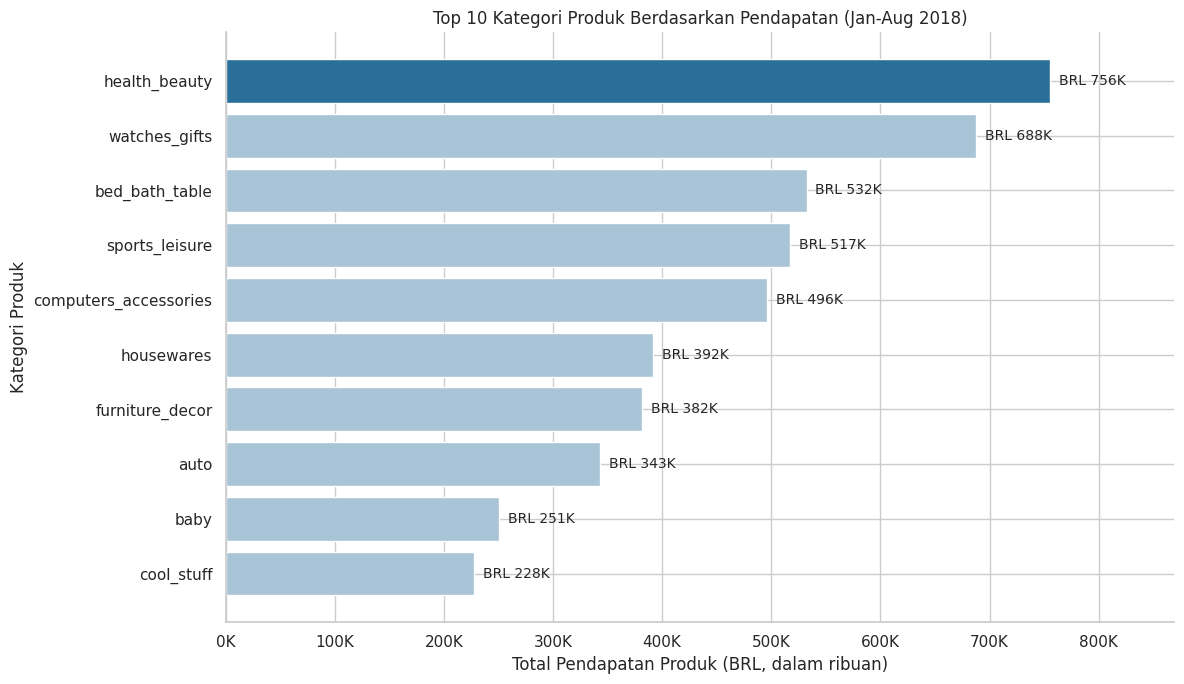

In [28]:
# Mengurutkan 10 kategori berdasarkan pendapatan 2018
plot_top_10 = top_10_categories.sort_values(
    by='revenue_2018',
    ascending=True
)

colors = ['#A9C4D6'] * len(plot_top_10)
colors[-1] = '#2A6F97'  # highlight kategori dengan pendapatan tertinggi

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(plot_top_10.index, plot_top_10['revenue_2018'], color=colors)

for bar, value in zip(bars, plot_top_10['revenue_2018']):
    ax.text(value + 8000, bar.get_y() + bar.get_height() / 2,
            f'BRL {value / 1000:,.0f}K', va='center', fontsize=10)

ax.set_title('Top 10 Kategori Produk Berdasarkan Pendapatan (Jan-Aug 2018)')
ax.set_xlabel('Total Pendapatan Produk (BRL, dalam ribuan)')
ax.set_ylabel('Kategori Produk')
ax.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'{x / 1000:,.0f}K')
)
ax.set_xlim(0, plot_top_10['revenue_2018'].max() * 1.15)
sns.despine()

plt.tight_layout()
plt.show()


Berdasarkan visualisasi, kategori health_beauty menjadi penyumbang pendapatan produk terbesar selama Januari-Agustus 2018, diikuti oleh watches_gifts dan bed_bath_table. Sementara itu, cool_stuff menempati posisi kesepuluh di antara kategori dengan pendapatan terbesar. Hasil ini menunjukkan bahwa kategori health_beauty dan watches_gifts memiliki kontribusi pendapatan yang cukup dominan dibandingkan kategori lainnya.

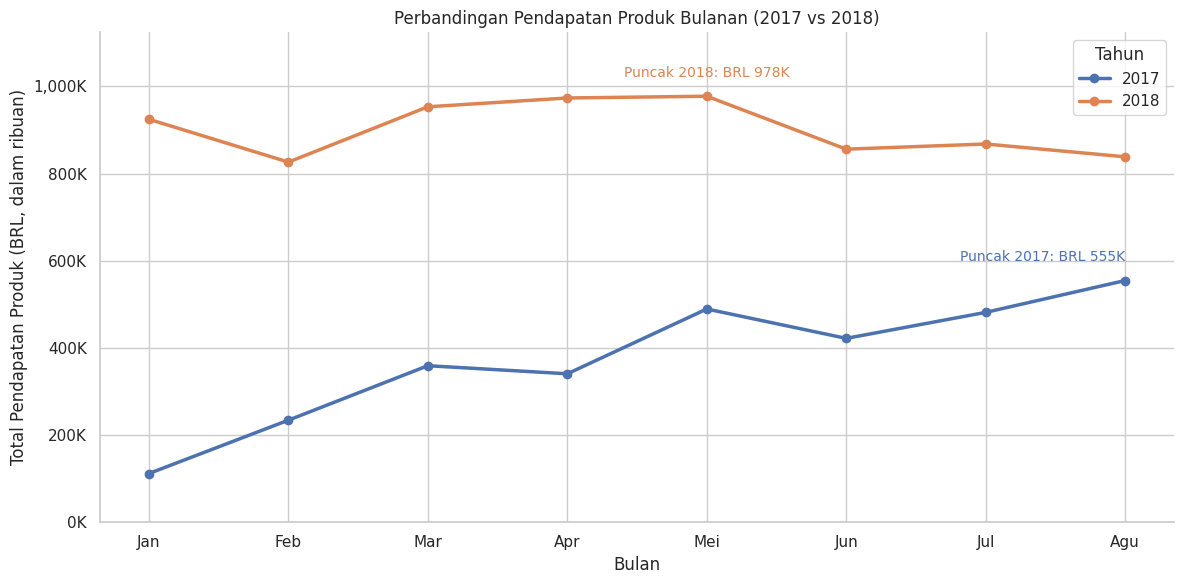

In [29]:
monthly_revenue_pivot = monthly_revenue.pivot(
    index='month',
    columns='year',
    values='total_revenue'
)

fig, ax = plt.subplots(figsize=(12, 6))
line_2017, = ax.plot(monthly_revenue_pivot.index, monthly_revenue_pivot[2017],
                     marker='o', linewidth=2.5, label='2017')
line_2018, = ax.plot(monthly_revenue_pivot.index, monthly_revenue_pivot[2018],
                     marker='o', linewidth=2.5, label='2018')

# Menandai bulan dengan pendapatan tertinggi pada tiap tahun
for year, color in [(2017, line_2017.get_color()), (2018, line_2018.get_color())]:
    peak_month = monthly_revenue_pivot[year].idxmax()
    peak_value = monthly_revenue_pivot[year].max()
    ax.annotate(f'Puncak {year}: BRL {peak_value / 1000:,.0f}K',
                xy=(peak_month, peak_value),
                xytext=(0, 14), textcoords='offset points',
                ha='right' if peak_month == monthly_revenue_pivot.index.max() else 'center',
                fontsize=10, color=color)

ax.set_title('Perbandingan Pendapatan Produk Bulanan (2017 vs 2018)')
ax.set_xlabel('Bulan')
ax.set_ylabel('Total Pendapatan Produk (BRL, dalam ribuan)')
ax.set_xticks(range(1, 9))
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu'])
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda y, _: f'{y / 1000:,.0f}K')
)
ax.set_ylim(0, monthly_revenue_pivot.max().max() * 1.15)
ax.legend(title='Tahun')
sns.despine()

plt.tight_layout()
plt.show()


Berdasarkan visualisasi, pendapatan produk pada Januari-Agustus 2018 selalu lebih tinggi dibandingkan periode yang sama pada 2017. Pada 2017, pendapatan menunjukkan kecenderungan meningkat hingga mencapai nilai tertinggi pada Agustus. Sementara itu, pada 2018 pendapatan tertinggi terjadi pada Mei, kemudian mengalami fluktuasi hingga Agustus. Secara keseluruhan, grafik menunjukkan adanya peningkatan pendapatan produk yang cukup signifikan pada 2018 dibandingkan 2017.

### Pertanyaan 2:

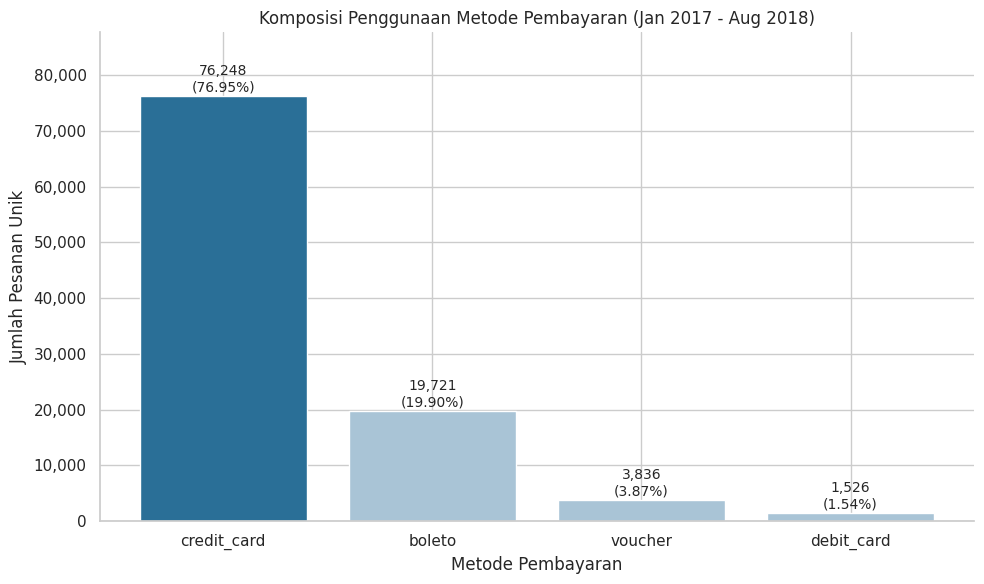

In [30]:
plot_payment_method = payment_method_summary.sort_values(
    by='total_orders',
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    plot_payment_method['payment_type'],
    plot_payment_method['total_orders'],
    color=['#2A6F97'] + ['#A9C4D6'] * (len(plot_payment_method) - 1)
)

for bar, orders, pct in zip(bars,
                            plot_payment_method['total_orders'],
                            plot_payment_method['order_percentage (%)']):
    ax.text(bar.get_x() + bar.get_width() / 2, orders + 800,
            f'{orders:,}\n({pct:.2f}%)', ha='center', fontsize=10)

ax.set_title('Komposisi Penggunaan Metode Pembayaran (Jan 2017 - Aug 2018)')
ax.set_xlabel('Metode Pembayaran')
ax.set_ylabel('Jumlah Pesanan Unik')
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda y, _: f'{y:,.0f}')
)
ax.set_ylim(0, plot_payment_method['total_orders'].max() * 1.15)
sns.despine()

plt.tight_layout()
plt.show()


Berdasarkan visualisasi, credit card merupakan metode pembayaran yang paling banyak digunakan selama Januari 2017 hingga Agustus 2018. Boleto menempati posisi kedua, diikuti voucher dan debit card. Perbedaan yang cukup besar menunjukkan bahwa credit card menjadi metode pembayaran yang paling dominan digunakan oleh pelanggan.

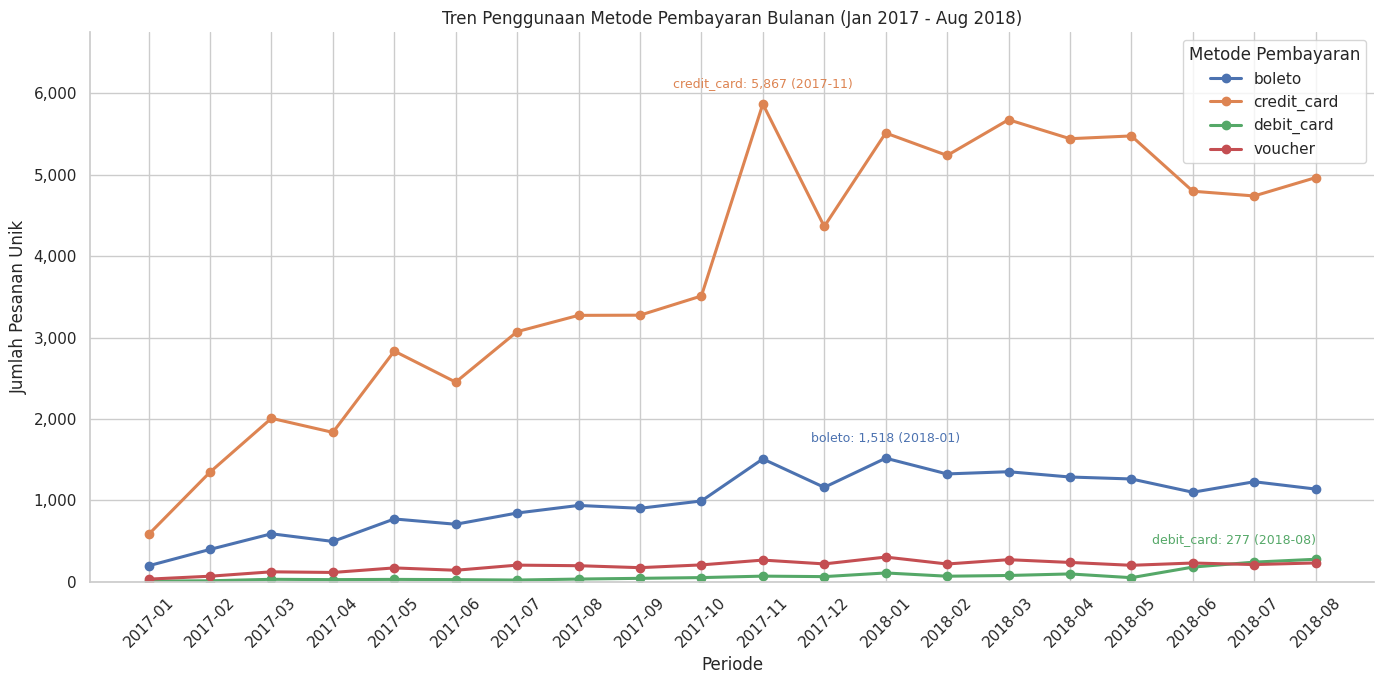

In [31]:
fig, ax = plt.subplots(figsize=(14, 7))

line_colors = {}
for payment_type in monthly_payment_pivot.columns.drop('total_orders'):
    line, = ax.plot(
        monthly_payment_pivot.index,
        monthly_payment_pivot[payment_type],
        marker='o',
        linewidth=2.2,
        label=payment_type
    )
    line_colors[payment_type] = line.get_color()

# Menandai bulan dengan penggunaan tertinggi untuk metode yang dibahas pada insight
for payment_type, offset in [('credit_card', 12), ('boleto', 12), ('debit_card', 12)]:
    series = monthly_payment_pivot[payment_type]
    peak_period = series.idxmax()
    ax.annotate(f'{payment_type}: {int(series.max()):,} ({peak_period})',
                xy=(peak_period, series.max()),
                xytext=(0, offset), textcoords='offset points',
                ha='right' if peak_period == series.index.max() else 'center',
                fontsize=9,
                color=line_colors[payment_type])

ax.set_title('Tren Penggunaan Metode Pembayaran Bulanan (Jan 2017 - Aug 2018)')
ax.set_xlabel('Periode')
ax.set_ylabel('Jumlah Pesanan Unik')
ax.tick_params(axis='x', rotation=45)
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda y, _: f'{y:,.0f}')
)
ax.set_ylim(0, monthly_payment_pivot['credit_card'].max() * 1.15)
ax.legend(title='Metode Pembayaran')
sns.despine()

plt.tight_layout()
plt.show()


Berdasarkan visualisasi, credit card menjadi metode pembayaran yang paling banyak digunakan setiap bulan, dengan jumlah penggunaan tertinggi pada November 2017. Boleto menempati posisi kedua dengan penggunaan tertinggi pada Januari 2018. Sementara itu, voucher dan debit card memiliki jumlah penggunaan yang relatif lebih rendah. Penggunaan debit card juga menunjukkan peningkatan pada beberapa bulan terakhir periode pengamatan

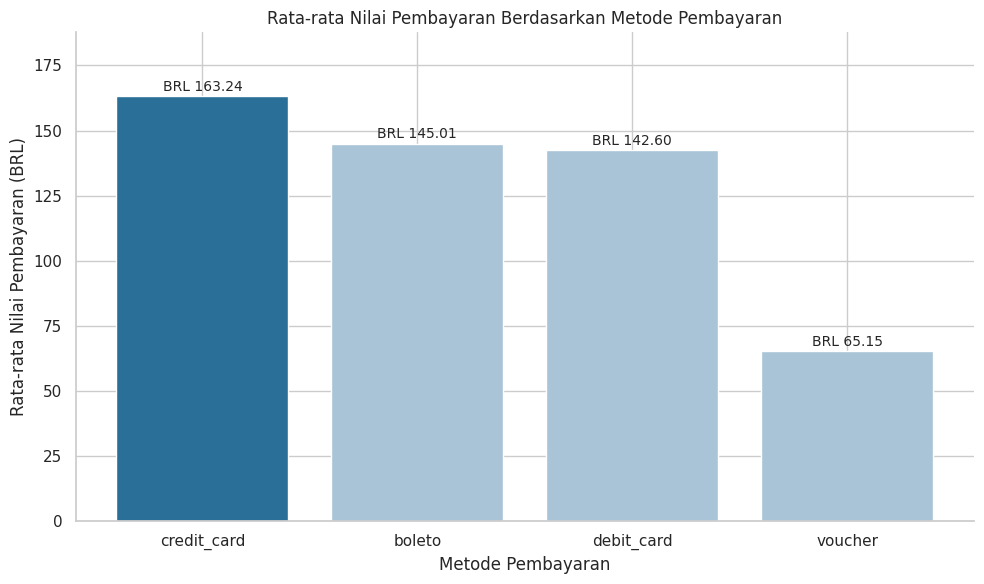

In [32]:
plot_payment_value = payment_value_summary.sort_values(
    by='average_payment_value',
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    plot_payment_value['payment_type'],
    plot_payment_value['average_payment_value'],
    color=['#2A6F97'] + ['#A9C4D6'] * (len(plot_payment_value) - 1)
)

for bar, value in zip(bars, plot_payment_value['average_payment_value']):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 2,
            f'BRL {value:,.2f}', ha='center', fontsize=10)

ax.set_title('Rata-rata Nilai Pembayaran Berdasarkan Metode Pembayaran')
ax.set_xlabel('Metode Pembayaran')
ax.set_ylabel('Rata-rata Nilai Pembayaran (BRL)')
ax.set_ylim(0, plot_payment_value['average_payment_value'].max() * 1.15)
sns.despine()

plt.tight_layout()
plt.show()


Berdasarkan visualisasi, credit card memiliki rata-rata nilai pembayaran tertinggi, diikuti oleh boleto dan debit card, sementara itu, voucher memiliki rata-rata nilai pembayaran terendah. Hasil ini menunjukkan adanya perbedaan rata-rata nilai pembayaran berdasarkan metode yang digunakan pelanggan.

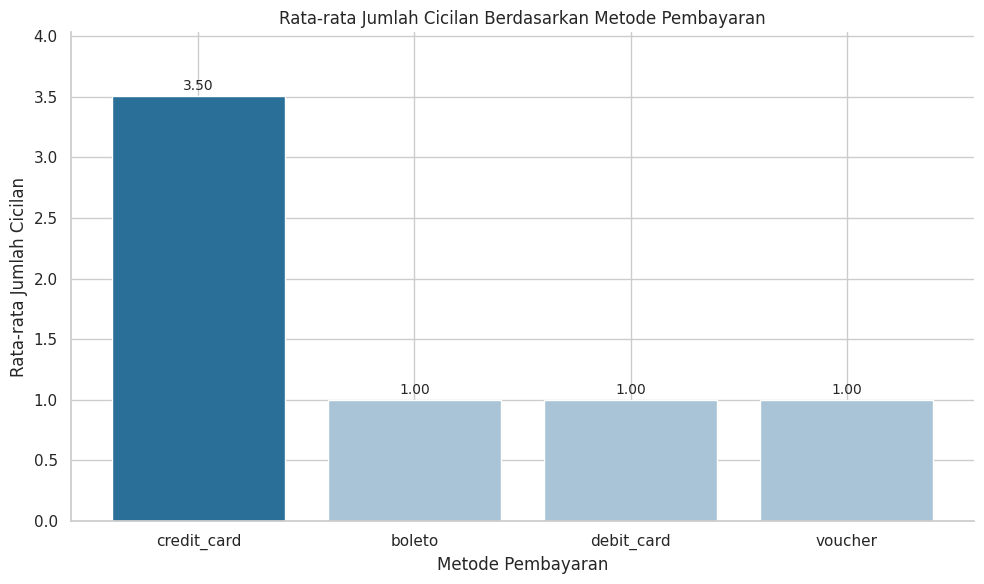

In [33]:
plot_installment = installment_summary.sort_values(
    by='average_installments',
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    plot_installment['payment_type'],
    plot_installment['average_installments'],
    color=['#2A6F97'] + ['#A9C4D6'] * (len(plot_installment) - 1)
)

for bar, value in zip(bars, plot_installment['average_installments']):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.05,
            f'{value:.2f}', ha='center', fontsize=10)

ax.set_title('Rata-rata Jumlah Cicilan Berdasarkan Metode Pembayaran')
ax.set_xlabel('Metode Pembayaran')
ax.set_ylabel('Rata-rata Jumlah Cicilan')
ax.set_ylim(0, plot_installment['average_installments'].max() * 1.15)
sns.despine()

plt.tight_layout()
plt.show()


Berdasarkan visualisasi, credit card memiliki rata-rata jumlah cicilan sebesar 3,5 kali. Sementara itu, boleto, debit card, dan voucher masing-masing memiliki rata-rata satu kali cicilan. Hal ini menunjukkan bahwa penggunaan fasilitas cicilan lebih banyak ditemukan pada transaksi yang menggunakan credit card.

**Insight:** (Opsional)
- Kategori health_beauty menjadi penyumbang pendapatan terbesar selama Januari-Agustus 2018, diikuti oleh watches_gifts dan bed_bath_table.
- Pendapatan produk pada 2018 selalu lebih tinggi dibandingkan periode yang sama pada 2017. Pendapatan tertinggi pada 2018 terjadi pada Mei.
- Credit card menjadi metode pembayaran paling dominan diikuti oleh boleto, voucher, dan debit card. Pola ini juga terlihat konsisten pada tren penggunaan bulanan.
- Credit card memiliki rata-rata nilai pembayaran tertinggi, sedangkan voucher memiliki rata-rata terendah.
- Penggunaan cicilan paling banyak ditemukan pada credit card dengan rata-rata 3,5 kali cicilan. Sementara itu, boleto, debit card, dan voucher umumnya menggunakan satu kali pembayaran.

## Analisis Lanjutan (Opsional)

### Binning dan Manual Grouping Nilai Transaksi

**Tujuan:** melengkapi Pertanyaan 2 dengan melihat bagaimana nilai transaksi berkaitan dengan metode pembayaran dan lama cicilan.

- **Binning** (`pd.cut`): total pembayaran setiap pesanan dibagi ke dalam lima rentang nilai.
- **Manual grouping**: jumlah cicilan kartu kredit dikelompokkan berdasarkan aturan bisnis (tanpa cicilan, cicilan pendek 2-6x, cicilan panjang lebih dari 6x), dan pesanan dikelompokkan menurut metode pembayarannya (satu metode atau lebih dari satu metode).
- **Cakupan:** sama dengan Pertanyaan 2, yaitu Januari 2017 - Agustus 2018 (seluruh status pesanan, tanpa metode `not_defined`).

**Menyiapkan data per pesanan dan melakukan binning**

In [34]:
# Total pembayaran dan metode pembayaran untuk setiap pesanan
order_payment = (
    payments_method_bq2
    .groupby('order_id')
    .agg(
        total_payment=('payment_value', 'sum'),
        total_methods=('payment_type', 'nunique')
    )
)

# Manual grouping: satu metode pembayaran atau lebih dari satu metode
main_method = (
    payments_method_bq2
    .groupby('order_id')['payment_type']
    .first()
)
order_payment['payment_group'] = np.where(
    order_payment['total_methods'] > 1,
    'multi_method',
    main_method
)

# Binning: membagi total pembayaran pesanan ke dalam lima rentang nilai
value_bins = [0, 50, 100, 200, 500, np.inf]
value_labels = ['< BRL 50', 'BRL 50 - 100', 'BRL 100 - 200',
                'BRL 200 - 500', '> BRL 500']

order_payment['value_group'] = pd.cut(
    order_payment['total_payment'],
    bins=value_bins,
    labels=value_labels,
    right=False,
    include_lowest=True
)

# Ringkasan setiap rentang nilai
value_group_summary = (
    order_payment.groupby('value_group', observed=True)
    .agg(
        total_orders=('total_payment', 'count'),
        total_payment=('total_payment', 'sum'),
        average_payment=('total_payment', 'mean')
    )
    .reset_index()
)

value_group_summary['order_percentage (%)'] = (
    value_group_summary['total_orders'] /
    value_group_summary['total_orders'].sum() * 100
)
value_group_summary['payment_percentage (%)'] = (
    value_group_summary['total_payment'] /
    value_group_summary['total_payment'].sum() * 100
)

print('Jumlah pesanan yang dianalisis:', len(order_payment))
display(value_group_summary.round(2))


Jumlah pesanan yang dianalisis: 99090


,value_group,total_orders,total_payment,average_payment,order_percentage (%),payment_percentage (%)
0,< BRL 50,16860,621424.79,36.86,17.01,3.90
1,BRL 50 - 100,30238,2216095.90,73.29,30.52,13.90
2,BRL 100 - 200,31802,4515557.77,141.99,32.09,28.32
3,BRL 200 - 500,15917,4616185.03,290.02,16.06,28.95
4,> BRL 500,4273,3975217.08,930.31,4.31,24.93


In [35]:
# Komposisi metode pembayaran pada setiap rentang nilai pesanan (% per baris)
payment_group_order = ['credit_card', 'boleto', 'voucher',
                       'debit_card', 'multi_method']

method_by_value = (
    pd.crosstab(
        order_payment['value_group'],
        order_payment['payment_group'],
        normalize='index'
    ) * 100
)[payment_group_order]

display(method_by_value.round(2))


payment_group,credit_card,boleto,voucher,debit_card,multi_method
value_group,,,,,
< BRL 50,68.88,23.90,2.89,2.18,2.14
BRL 50 - 100,72.93,21.17,1.91,1.60,2.39
BRL 100 - 200,76.43,18.74,1.17,1.36,2.30
BRL 200 - 500,79.10,16.70,0.75,1.24,2.21
> BRL 500,80.60,15.73,0.89,1.03,1.76


In [36]:
# Manual grouping jumlah cicilan untuk pesanan dengan pembayaran kartu kredit
credit_card_orders = (
    payments_installments_bq2[
        payments_installments_bq2['payment_type'] == 'credit_card'
    ]
    .groupby('order_id')
    .agg(
        max_installments=('payment_installments', 'max'),
        credit_card_value=('payment_value', 'sum')
    )
)

installment_order = ['Tanpa cicilan (1x)',
                     'Cicilan pendek (2-6x)',
                     'Cicilan panjang (>6x)']

credit_card_orders['installment_group'] = pd.Categorical(
    np.select(
        [
            credit_card_orders['max_installments'] == 1,
            credit_card_orders['max_installments'] <= 6
        ],
        [installment_order[0], installment_order[1]],
        default=installment_order[2]
    ),
    categories=installment_order,
    ordered=True
)

# Binning nilai pembayaran kartu kredit dengan rentang yang sama
credit_card_orders['value_group'] = pd.cut(
    credit_card_orders['credit_card_value'],
    bins=value_bins,
    labels=value_labels,
    right=False,
    include_lowest=True
)

installment_summary_group = (
    credit_card_orders.groupby('installment_group', observed=True)
    .agg(
        total_orders=('credit_card_value', 'count'),
        average_value=('credit_card_value', 'mean'),
        median_value=('credit_card_value', 'median')
    )
    .reset_index()
)
installment_summary_group['order_percentage (%)'] = (
    installment_summary_group['total_orders'] /
    installment_summary_group['total_orders'].sum() * 100
)

installment_by_value = (
    pd.crosstab(
        credit_card_orders['value_group'],
        credit_card_orders['installment_group'],
        normalize='index'
    ) * 100
)

print('Jumlah pesanan dengan kartu kredit:', len(credit_card_orders))
display(installment_summary_group.round(2))
display(installment_by_value.round(2))


Jumlah pesanan dengan kartu kredit: 76246


,installment_group,total_orders,average_value,median_value,order_percentage (%)
0,Tanpa cicilan (1x),25276,96.19,68.22,33.15
1,Cicilan pendek (2-6x),38858,154.25,116.94,50.96
2,Cicilan panjang (>6x),12112,335.88,206.08,15.89


installment_group,Tanpa cicilan (1x),Cicilan pendek (2-6x),Cicilan panjang (>6x)
value_group,,,
< BRL 50,63.59,36.40,0.02
BRL 50 - 100,42.80,49.89,7.31
BRL 100 - 200,22.07,60.66,17.27
BRL 200 - 500,12.96,54.65,32.39
> BRL 500,7.86,31.02,61.12


**Visualisasi binning dan manual grouping**

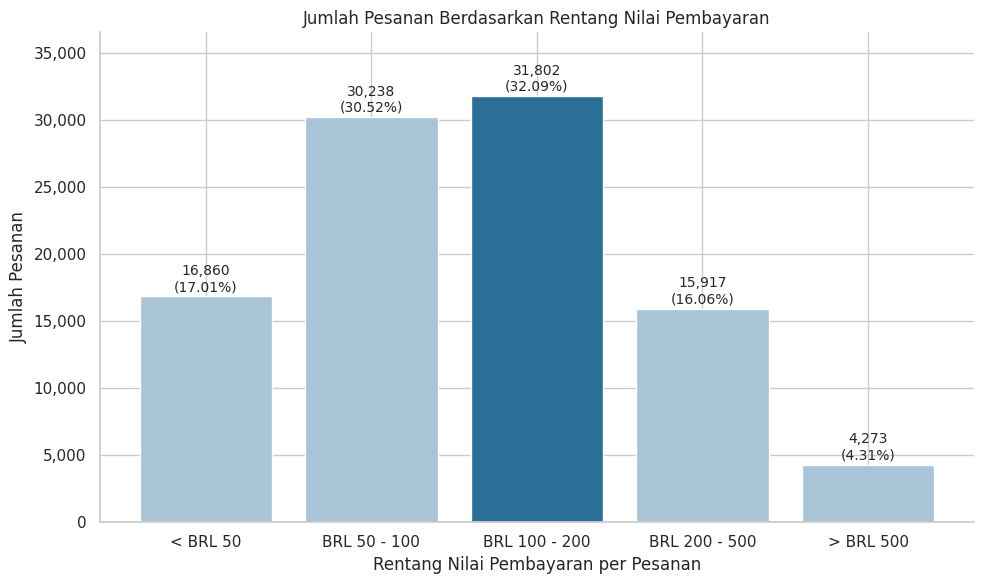

In [37]:
plot_value_group = value_group_summary.copy()

colors = ['#A9C4D6'] * len(plot_value_group)
colors[plot_value_group['total_orders'].idxmax()] = '#2A6F97'

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(plot_value_group['value_group'].astype(str),
              plot_value_group['total_orders'], color=colors)

for bar, orders, pct in zip(bars,
                            plot_value_group['total_orders'],
                            plot_value_group['order_percentage (%)']):
    ax.text(bar.get_x() + bar.get_width() / 2, orders + 400,
            f'{orders:,}\n({pct:.2f}%)', ha='center', fontsize=10)

ax.set_title('Jumlah Pesanan Berdasarkan Rentang Nilai Pembayaran')
ax.set_xlabel('Rentang Nilai Pembayaran per Pesanan')
ax.set_ylabel('Jumlah Pesanan')
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda y, _: f'{y:,.0f}')
)
ax.set_ylim(0, plot_value_group['total_orders'].max() * 1.15)
sns.despine()

plt.tight_layout()
plt.show()


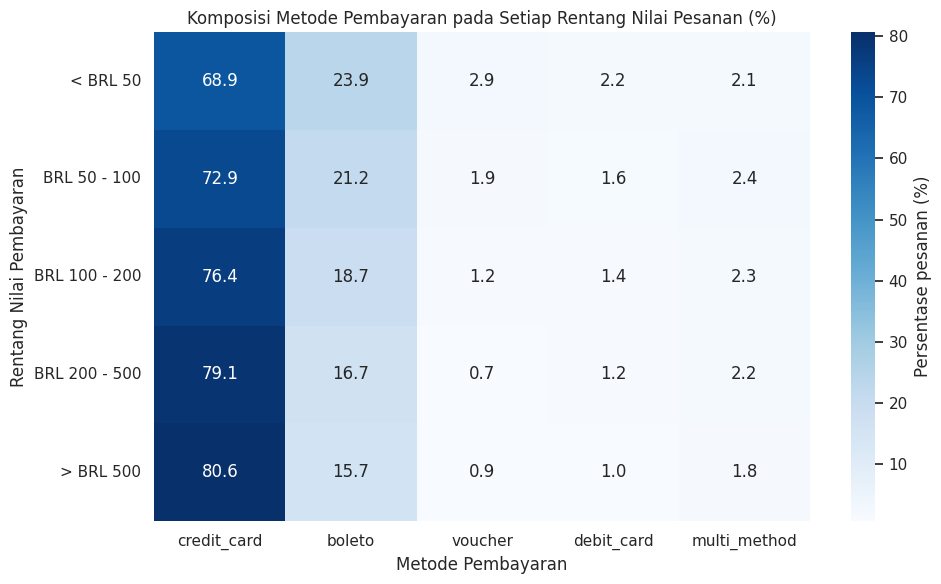

In [38]:
plt.figure(figsize=(10, 6))
sns.heatmap(
    method_by_value,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    cbar_kws={'label': 'Persentase pesanan (%)'}
)

plt.title('Komposisi Metode Pembayaran pada Setiap Rentang Nilai Pesanan (%)')
plt.xlabel('Metode Pembayaran')
plt.ylabel('Rentang Nilai Pembayaran')
plt.tight_layout()
plt.show()


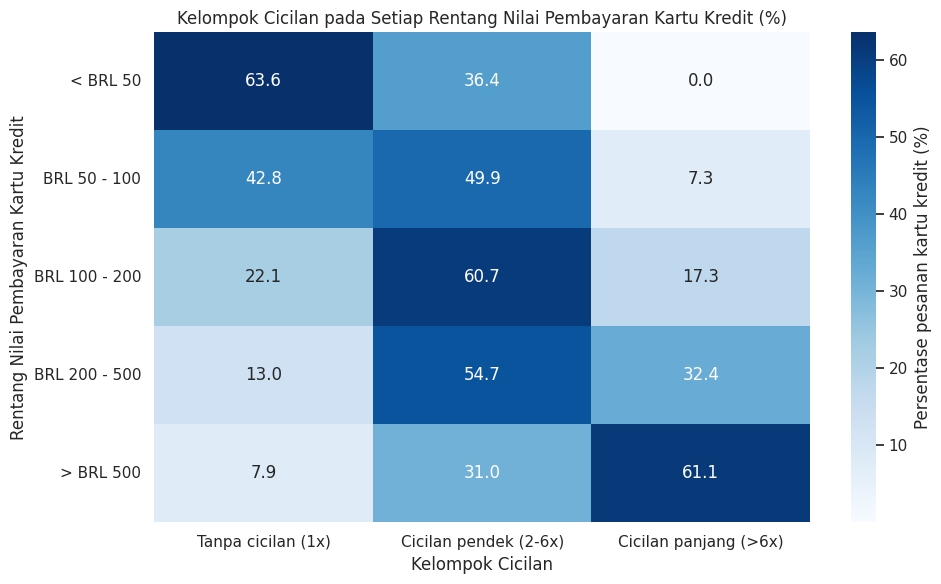

In [39]:
plt.figure(figsize=(10, 6))
sns.heatmap(
    installment_by_value,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    cbar_kws={'label': 'Persentase pesanan kartu kredit (%)'}
)

plt.title('Kelompok Cicilan pada Setiap Rentang Nilai Pembayaran Kartu Kredit (%)')
plt.xlabel('Kelompok Cicilan')
plt.ylabel('Rentang Nilai Pembayaran Kartu Kredit')
plt.tight_layout()
plt.show()


**Insight:** (Opsional)
- Analisis ini memakai 99.090 pesanan. Dua pesanan dari Pertanyaan 2 tidak ikut karena hanya memiliki metode pembayaran `not_defined`.
- Pesanan terbanyak berada pada rentang BRL 100 - 200 (31.802 pesanan atau 32,09%), disusul BRL 50 - 100 (30.238 pesanan atau 30,52%). Kedua rentang ini mencakup 62,61% seluruh pesanan.
- Kontribusi nilai pembayaran tidak sejalan dengan jumlah pesanan. Pesanan di atas BRL 500 hanya 4,31% dari seluruh pesanan, tetapi menyumbang 24,93% total nilai pembayaran. Sebaliknya, pesanan di bawah BRL 50 mencakup 17,01% pesanan, tetapi hanya menyumbang 3,90% nilai pembayaran.
- Semakin besar nilai pesanan, semakin dominan kartu kredit. Penggunaannya naik dari 68,88% pada pesanan di bawah BRL 50 menjadi 80,60% pada pesanan di atas BRL 500, sedangkan boleto turun dari 23,90% menjadi 15,73%. Voucher paling sering muncul pada pesanan kecil (2,89%).
- Dari 76.246 pesanan kartu kredit, 50,96% memakai cicilan pendek (2-6x), 33,15% tanpa cicilan, dan 15,89% memakai cicilan panjang (lebih dari 6x). Rata-rata nilai pembayaran kartu kredit naik seiring lamanya cicilan, yaitu BRL 96,19 (tanpa cicilan), BRL 154,25 (cicilan pendek), dan BRL 335,88 (cicilan panjang).
- Pada pesanan kartu kredit di atas BRL 500, 61,12% memakai cicilan panjang, sedangkan pada pesanan di bawah BRL 50 hampir tidak ada (0,02%). Pola ini menunjukkan cicilan panjang banyak dipakai untuk transaksi bernilai besar. Hubungan ini bersifat pola pada data (asosiasi) dan tidak membuktikan bahwa cicilan menyebabkan nilai transaksi lebih besar.


### Analisis RFM (Recency, Frequency, Monetary)

**Tujuan:** mengelompokkan pelanggan berdasarkan perilaku pembeliannya agar bisnis dapat menentukan segmen yang perlu dipertahankan atau diaktifkan kembali.

- **Recency:** jumlah hari sejak pembelian terakhir pelanggan sampai tanggal acuan (1 September 2018, sehari setelah periode analisis berakhir).
- **Frequency:** jumlah pesanan unik yang dilakukan pelanggan.
- **Monetary:** total nilai pembayaran seluruh pesanan pelanggan.
- **Cakupan:** pesanan berstatus delivered pada Januari 2017 - Agustus 2018, sama seperti Pertanyaan 1.
- **Identitas pelanggan:** memakai `customer_unique_id`, karena `customer_id` berubah pada setiap pesanan sehingga tidak dapat dipakai untuk mengenali pelanggan yang sama.
- **Pengelompokan:** berbasis aturan (rule-based) dan binning, tanpa algoritma machine learning.

**Menggabungkan data pelanggan**

In [40]:
customers_df = pd.read_csv('customers_dataset.csv')
print('Jumlah baris customers:', len(customers_df))
print('Jumlah customer_id unik:', customers_df['customer_id'].nunique())
print('Jumlah customer_unique_id unik:',
      customers_df['customer_unique_id'].nunique())
print('Missing values:', customers_df[['customer_id', 'customer_unique_id']].isnull().sum().sum())


Jumlah baris customers: 99441
Jumlah customer_id unik: 99441
Jumlah customer_unique_id unik: 96096
Missing values: 0


In [41]:
# Pesanan delivered pada Januari 2017 - Agustus 2018
rfm_orders = orders_clean[
    (orders_clean['order_status'] == 'delivered') &
    (orders_clean['order_purchase_timestamp'] >= '2017-01-01') &
    (orders_clean['order_purchase_timestamp'] < '2018-09-01')
][['order_id', 'customer_id', 'order_purchase_timestamp']]

# Menambahkan identitas pelanggan
rfm_orders = rfm_orders.merge(
    customers_df[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='inner'
)

# Total pembayaran per pesanan (diagregasi dulu agar tidak menggandakan nilai)
order_value = (
    payments_clean.groupby('order_id')['payment_value']
    .sum()
    .reset_index()
)
rfm_orders = rfm_orders.merge(order_value, on='order_id', how='left')

print('Jumlah pesanan:', rfm_orders['order_id'].nunique())
print('Pesanan tanpa data pembayaran:',
      rfm_orders['payment_value'].isnull().sum())


Jumlah pesanan: 96211
Pesanan tanpa data pembayaran: 0


In [42]:
reference_date = pd.Timestamp('2018-09-01')

rfm = (
    rfm_orders.groupby('customer_unique_id')
    .agg(
        last_purchase=('order_purchase_timestamp', 'max'),
        frequency=('order_id', 'nunique'),
        monetary=('payment_value', 'sum')
    )
    .reset_index()
)

rfm['recency'] = (reference_date - rfm['last_purchase']).dt.days

print('Jumlah pelanggan unik:', len(rfm))
print('Persentase pelanggan yang berbelanja lebih dari sekali:',
      round((rfm['frequency'] > 1).mean() * 100, 2), '%')

print('\nDistribusi frequency:')
print(rfm['frequency'].value_counts().sort_index().to_string())

display(rfm[['recency', 'frequency', 'monetary']].describe().round(2))


Jumlah pelanggan unik: 93104
Persentase pelanggan yang berbelanja lebih dari sekali: 3.0 %

Distribusi frequency:
frequency
1     90315
2      2562
3       180
4        28
5         9
6         5
7         3
9         1
15        1


,recency,frequency,monetary
count,93104.00,93104.00,93104.00
mean,238.24,1.03,165.15
std,150.95,0.21,226.38
min,2.00,1.00,9.59
25%,116.00,1.00,63.04
50%,220.00,1.00,107.78
75%,347.00,1.00,182.50
max,603.00,15.00,13664.08


**Pengelompokan RFM dengan binning dan aturan bisnis**

Hampir seluruh pelanggan hanya berbelanja satu kali, sehingga Frequency tidak dapat dibagi dengan kuantil (nilainya sama untuk sebagian besar pelanggan). Karena itu Frequency dikelompokkan secara manual, sedangkan Recency dibagi dengan `pd.cut` dan Monetary dengan `pd.qcut`. Batas segmen di bawah ini merupakan asumsi bisnis yang dapat disesuaikan.

| Segmen | Aturan |
|---|---|
| Loyal Aktif | Frequency >= 2 dan Recency <= 180 hari |
| Loyal Tidak Aktif | Frequency >= 2 dan Recency > 180 hari |
| Big Spender | Frequency = 1, Monetary termasuk 20% tertinggi, dan Recency <= 180 hari |
| Pelanggan Baru | Frequency = 1 dan Recency <= 90 hari |
| Perlu Reaktivasi | Frequency = 1 dan Recency 91 - 365 hari |
| Hilang | Frequency = 1 dan Recency > 365 hari |

Aturan diterapkan berurutan dari atas ke bawah sehingga setiap pelanggan hanya masuk ke satu segmen.

In [43]:
# Binning Recency dan Monetary, manual grouping Frequency
rfm['recency_group'] = pd.cut(
    rfm['recency'],
    bins=[-1, 90, 180, 365, np.inf],
    labels=['0-90 hari', '91-180 hari', '181-365 hari', '> 365 hari']
)

rfm['frequency_group'] = np.select(
    [rfm['frequency'] == 1, rfm['frequency'] == 2],
    ['1 kali', '2 kali'],
    default='>= 3 kali'
)

rfm['monetary_group'] = pd.qcut(
    rfm['monetary'],
    q=[0, 0.5, 0.8, 1],
    labels=['Rendah', 'Menengah', 'Tinggi']
)

# Segmentasi pelanggan berbasis aturan (dievaluasi berurutan)
segment_order = ['Loyal Aktif', 'Loyal Tidak Aktif', 'Big Spender',
                 'Pelanggan Baru', 'Perlu Reaktivasi', 'Hilang']

rfm['segment'] = pd.Categorical(
    np.select(
        [
            (rfm['frequency'] >= 2) & (rfm['recency'] <= 180),
            (rfm['frequency'] >= 2) & (rfm['recency'] > 180),
            (rfm['monetary_group'] == 'Tinggi') & (rfm['recency'] <= 180),
            rfm['recency'] <= 90,
            rfm['recency'] <= 365
        ],
        segment_order[:5],
        default=segment_order[5]
    ),
    categories=segment_order,
    ordered=True
)

rfm_summary = (
    rfm.groupby('segment', observed=True)
    .agg(
        total_customers=('customer_unique_id', 'count'),
        avg_recency=('recency', 'mean'),
        avg_frequency=('frequency', 'mean'),
        avg_monetary=('monetary', 'mean'),
        total_monetary=('monetary', 'sum')
    )
    .reset_index()
)

rfm_summary['customer_percentage (%)'] = (
    rfm_summary['total_customers'] /
    rfm_summary['total_customers'].sum() * 100
)
rfm_summary['monetary_percentage (%)'] = (
    rfm_summary['total_monetary'] /
    rfm_summary['total_monetary'].sum() * 100
)

display(rfm_summary.round(2))


,segment,total_customers,avg_recency,avg_frequency,avg_monetary,total_monetary,customer_percentage (%),monetary_percentage (%)
0,Loyal Aktif,1217,91.44,2.15,321.94,391805.50,1.31,2.55
1,Loyal Tidak Aktif,1572,321.50,2.08,298.31,468949.06,1.69,3.05
2,Big Spender,7017,94.11,1.00,449.49,3154046.00,7.54,20.51
3,Pelanggan Baru,14261,45.44,1.00,96.22,1372180.94,15.32,8.92
4,Perlu Reaktivasi,48819,223.91,1.00,138.67,6769759.54,52.43,44.03
5,Hilang,20218,461.22,1.00,159.22,3219134.40,21.72,20.94


**Visualisasi segmentasi RFM**

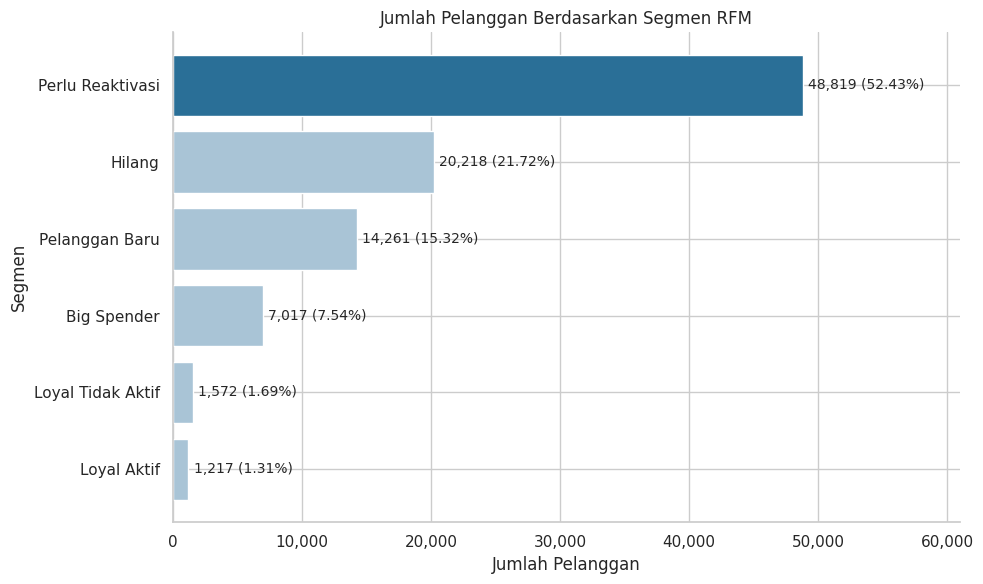

In [44]:
plot_rfm = rfm_summary.sort_values(by='total_customers', ascending=True)

colors = ['#A9C4D6'] * len(plot_rfm)
colors[-1] = '#2A6F97'

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot_rfm['segment'].astype(str),
               plot_rfm['total_customers'], color=colors)

for bar, customers, pct in zip(bars,
                               plot_rfm['total_customers'],
                               plot_rfm['customer_percentage (%)']):
    ax.text(customers + 400, bar.get_y() + bar.get_height() / 2,
            f'{customers:,} ({pct:.2f}%)', va='center', fontsize=10)

ax.set_title('Jumlah Pelanggan Berdasarkan Segmen RFM')
ax.set_xlabel('Jumlah Pelanggan')
ax.set_ylabel('Segmen')
ax.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')
)
ax.set_xlim(0, plot_rfm['total_customers'].max() * 1.25)
sns.despine()

plt.tight_layout()
plt.show()


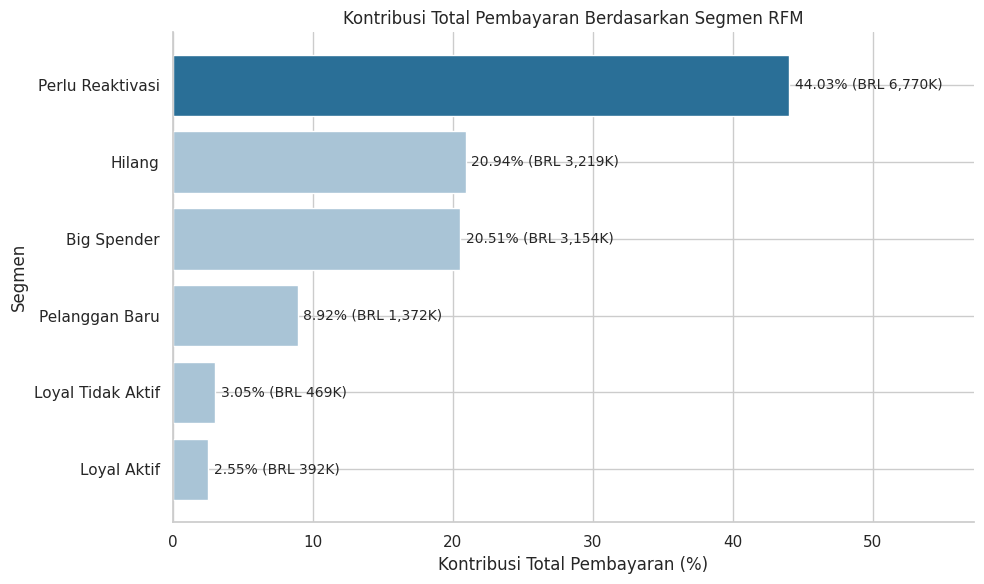

In [45]:
plot_rfm_monetary = rfm_summary.sort_values(
    by='monetary_percentage (%)',
    ascending=True
)

colors = ['#A9C4D6'] * len(plot_rfm_monetary)
colors[-1] = '#2A6F97'

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot_rfm_monetary['segment'].astype(str),
               plot_rfm_monetary['monetary_percentage (%)'], color=colors)

for bar, pct, total in zip(bars,
                           plot_rfm_monetary['monetary_percentage (%)'],
                           plot_rfm_monetary['total_monetary']):
    ax.text(pct + 0.4, bar.get_y() + bar.get_height() / 2,
            f'{pct:.2f}% (BRL {total / 1000:,.0f}K)',
            va='center', fontsize=10)

ax.set_title('Kontribusi Total Pembayaran Berdasarkan Segmen RFM')
ax.set_xlabel('Kontribusi Total Pembayaran (%)')
ax.set_ylabel('Segmen')
ax.set_xlim(0, plot_rfm_monetary['monetary_percentage (%)'].max() * 1.3)
sns.despine()

plt.tight_layout()
plt.show()


**Insight:** (Opsional)
- Terdapat 93.104 pelanggan unik pada pesanan delivered Januari 2017 - Agustus 2018. Hanya 3,00% (2.789 pelanggan) yang berbelanja lebih dari sekali, sehingga sebagian besar pelanggan memiliki Frequency yang sama (1 kali). Hal ini yang membuat segmentasi dibuat berbasis aturan, bukan kuantil.
- Segmen terbesar adalah Perlu Reaktivasi dengan 48.819 pelanggan (52,43%) dan kontribusi 44,03% dari total pembayaran (BRL 6.769.759,54). Segmen Hilang berisi 20.218 pelanggan (21,72%) dan Pelanggan Baru 14.261 pelanggan (15,32%).
- Big Spender hanya 7.017 pelanggan (7,54%), tetapi menyumbang 20,51% total pembayaran dengan rata-rata pembayaran tertinggi, yaitu BRL 449,49 per pelanggan.
- Segmen Loyal (Aktif dan Tidak Aktif) berjumlah 2.789 pelanggan (3,00%) dan menyumbang 5,60% total pembayaran. Rata-rata pembayarannya (BRL 321,94 dan BRL 298,31) sekitar dua kali lipat pelanggan yang hanya berbelanja sekali pada segmen Perlu Reaktivasi (BRL 138,67).
- Segmen Loyal Tidak Aktif (1.572 pelanggan, rata-rata Recency 321,50 hari) lebih banyak daripada Loyal Aktif (1.217 pelanggan), artinya sebagian pelanggan yang pernah berbelanja ulang tidak kembali dalam lebih dari 180 hari.
- Batas segmen (90, 180, dan 365 hari serta 20% Monetary tertinggi) merupakan asumsi bisnis dan Recency dihitung dari 1 September 2018, sehingga hasilnya dapat berubah bila batas tersebut disesuaikan.


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pendapatan berdasarkan kategori produk: Selama Januari hingga Agustus 2018, kategori health_beauty menjadi kategori dengan pendapatan terbesar, yaitu sebesar BRL 755.724,50, diikuti oleh watches_gifts sebesar BRL 687.855,20 dan bed_bath_table sebesar BRL 532.358,85. Secara keseluruhan, total pendapatan penjualan produk pada periode tersebut mencapai BRL 7.218.125,12, meningkat sebesar 141,13% dibandingkan periode Januari hingga Agustus 2017. Hasil ini menunjukkan adanya peningkatan pendapatan penjualan produk yang cukup besar pada tahun 2018.
- **Conclusion pertanyaan 2:** Penggunaan metode pembayaran pelanggan: Kartu kredit (credit card) merupakan metode pembayaran yang paling banyak digunakan, dengan 76.248 pesanan atau sekitar 76,95% dari total 99.092 pesanan. Selanjutnya, metode boleto digunakan pada 19.721 pesanan, voucher pada 3.836 pesanan, dan kartu debit pada 1.526 pesanan. Rata-rata nilai pembayaran tertinggi terdapat pada kartu kredit sebesar BRL 163,24 per catatan pembayaran, sedangkan voucher memiliki rata-rata terendah sebesar BRL 65,15. Dari sisi cicilan, kartu kredit memiliki rata-rata 3,5 cicilan, sementara metode pembayaran lainnya umumnya menggunakan satu cicilan. Perlu diperhatikan bahwa persentase penggunaan metode pembayaran dapat berjumlah lebih dari 100% karena satu pesanan memungkinkan menggunakan lebih dari satu metode pembayaran (2.241 pesanan memakai lebih dari satu metode). Analisis ini mencakup seluruh status pesanan, sedangkan Pertanyaan 1 hanya mencakup pesanan delivered.
- **Analisis lanjutan menggunakan Binning dan Manual Grouping**: Pesanan terbanyak berada pada rentang BRL 100 - 200 (32,09%) dan BRL 50 - 100 (30,52%), tetapi pesanan di atas BRL 500 yang hanya 4,31% dari seluruh pesanan menyumbang 24,93% total nilai pembayaran. Semakin besar nilai pesanan, semakin tinggi penggunaan kartu kredit (68,88% pada pesanan di bawah BRL 50 menjadi 80,60% pada pesanan di atas BRL 500) dan semakin besar pula porsi cicilan panjang, yaitu 61,12% pada pesanan kartu kredit di atas BRL 500 dibandingkan 0,02% pada pesanan di bawah BRL 50.
- **Analisis lanjutan menggunakan RFM**: Hanya 3,00% dari 93.104 pelanggan yang berbelanja lebih dari sekali. Segmen Perlu Reaktivasi merupakan yang terbesar (52,43% pelanggan dan 44,03% total pembayaran), sedangkan segmen Big Spender (7,54% pelanggan) menyumbang 20,51% total pembayaran dengan rata-rata BRL 449,49 per pelanggan. Segmen Loyal hanya 3,00% pelanggan, tetapi rata-rata pembayarannya sekitar dua kali lipat pelanggan yang berbelanja sekali.

**Rekomendasi Action Item:**
- **Memprioritaskan kategori produk dengan pendapatan tinggi**. memperhatikan ketersediaan stok dan meningkatkan promosi pada kategori *health_beauty*, *watches_gifts*, dan *bed_bath_table* karena ketiganya memiliki pendapatan terbesar.
- **Mengembangkan strategi promosi berdasarkan metode pembayaran**. Karena kartu kredit menjadi metode pembayaran yang paling banyak digunakan, bisnis dapat mempertimbangkan untuk bekerja sama dengan layanan kartu kredit melalui program cicilan atau promosi pembayaran. Metode lain seperti boleto dan voucher juga dapat tetap didukung untuk memberikan alternatif pembayaran kepada pelanggan.
- **Menyesuaikan promosi cicilan dengan nilai transaksi**. Cicilan panjang banyak dipakai pada pesanan bernilai besar, sehingga penawaran cicilan tenor panjang dapat difokuskan pada transaksi bernilai di atas BRL 500, sedangkan pesanan bernilai kecil dapat didukung dengan metode yang sederhana seperti boleto atau voucher. Efektivitasnya tetap perlu diuji, karena hasil analisis hanya menunjukkan pola, bukan sebab-akibat.
- **Menjalankan kampanye reaktivasi pada segmen Perlu Reaktivasi dan Hilang**. Kedua segmen mencakup 74,15% pelanggan dan 64,97% total pembayaran. Pelanggan Perlu Reaktivasi (Recency 91 - 365 hari) terakhir berbelanja lebih baru daripada segmen Hilang (lebih dari 365 hari), sehingga lebih mudah diaktifkan kembali dan layak diprioritaskan.
- **Mendorong pembelian ulang dan menjaga pelanggan bernilai tinggi**. Karena hanya 3,00% pelanggan yang berbelanja ulang, program seperti voucher pembelian kedua atau poin loyalitas dapat dipertimbangkan. Segmen Big Spender dan Loyal Aktif perlu dipertahankan dengan layanan prioritas atau penawaran khusus.

In [48]:
import os
os.makedirs('data', exist_ok=True)

# Membuat salinan dataset customers
customers_clean = customers_df.copy()

In [49]:
# Menyimpan dataset yang sudah dibersihkan
orders_clean.to_csv('data/orders_dataset.csv', index=False)
order_items_clean.to_csv('data/order_items_dataset.csv', index=False)
products_clean.to_csv('data/products_dataset.csv', index=False)
category_clean.to_csv('data/product_category_name_translation.csv', index=False)
payments_clean.to_csv('data/order_payments_dataset.csv', index=False)
customers_clean.to_csv('data/customers_dataset.csv', index=False)

print("Seluruh dataset berhasil disimpan!")

Seluruh dataset berhasil disimpan!
